# Support Vector Machines and Kernels

![SVM.png](Assets/SVM.png)

# Obiectivele cursului
- Aplicarea metodei vectorilor de suport (SVM) — un algoritm popular utilizat pentru sarcini de clasificare
- Recunoașterea similitudinii dintre SVM și regresia logistică
- Calcularea funcției de pierdere pentru SVM
- Aplicarea regularizării în SVM și studierea recomandărilor privind obținerea unei clasificări neliniare cu ajutorul SVM

## Introducere
În aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține o măsură a calității (de la 3 la 9, unde scorul cel mai mare indică cea mai bună calitate) și culoarea (roșu sau alb). Numele fișierului: `Wine_Quality_Data.csv`.

In [1]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler

from sklearnex import patch_sklearn
patch_sklearn()

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Întrebarea 1
* Importul datelor.
* Creați variabila țintă `y` sub forma unei coloane cu valori 1/0, unde 1 înseamnă vin roșu.
* Creați un grafic pereche pentru setul de date.
* Creați un grafic cu bare care să ilustreze corelația dintre fiecare coloană și `y`.
* Selectați cele două câmpuri cu cea mai mare corelație (folosind valorile corelației absolute) și creați `X`.
* Folosiți MinMaxScaler pentru a scala `X`. Rețineți că rezultatul va fi un np.array. Transformați-l din nou într-un DataFrame și redenumiți coloanele în consecință.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Importul datelor (fisierul CSV se afla in acelasi director cu notebook-ul)
data = pd.read_csv('Wine_Quality_Data.csv')
print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
# Variabila tinta: 1 = vin rosu, 0 = vin alb
y = (data.color == 'red').astype(int)
y.value_counts()

color
0    4898
1    1599
Name: count, dtype: int64

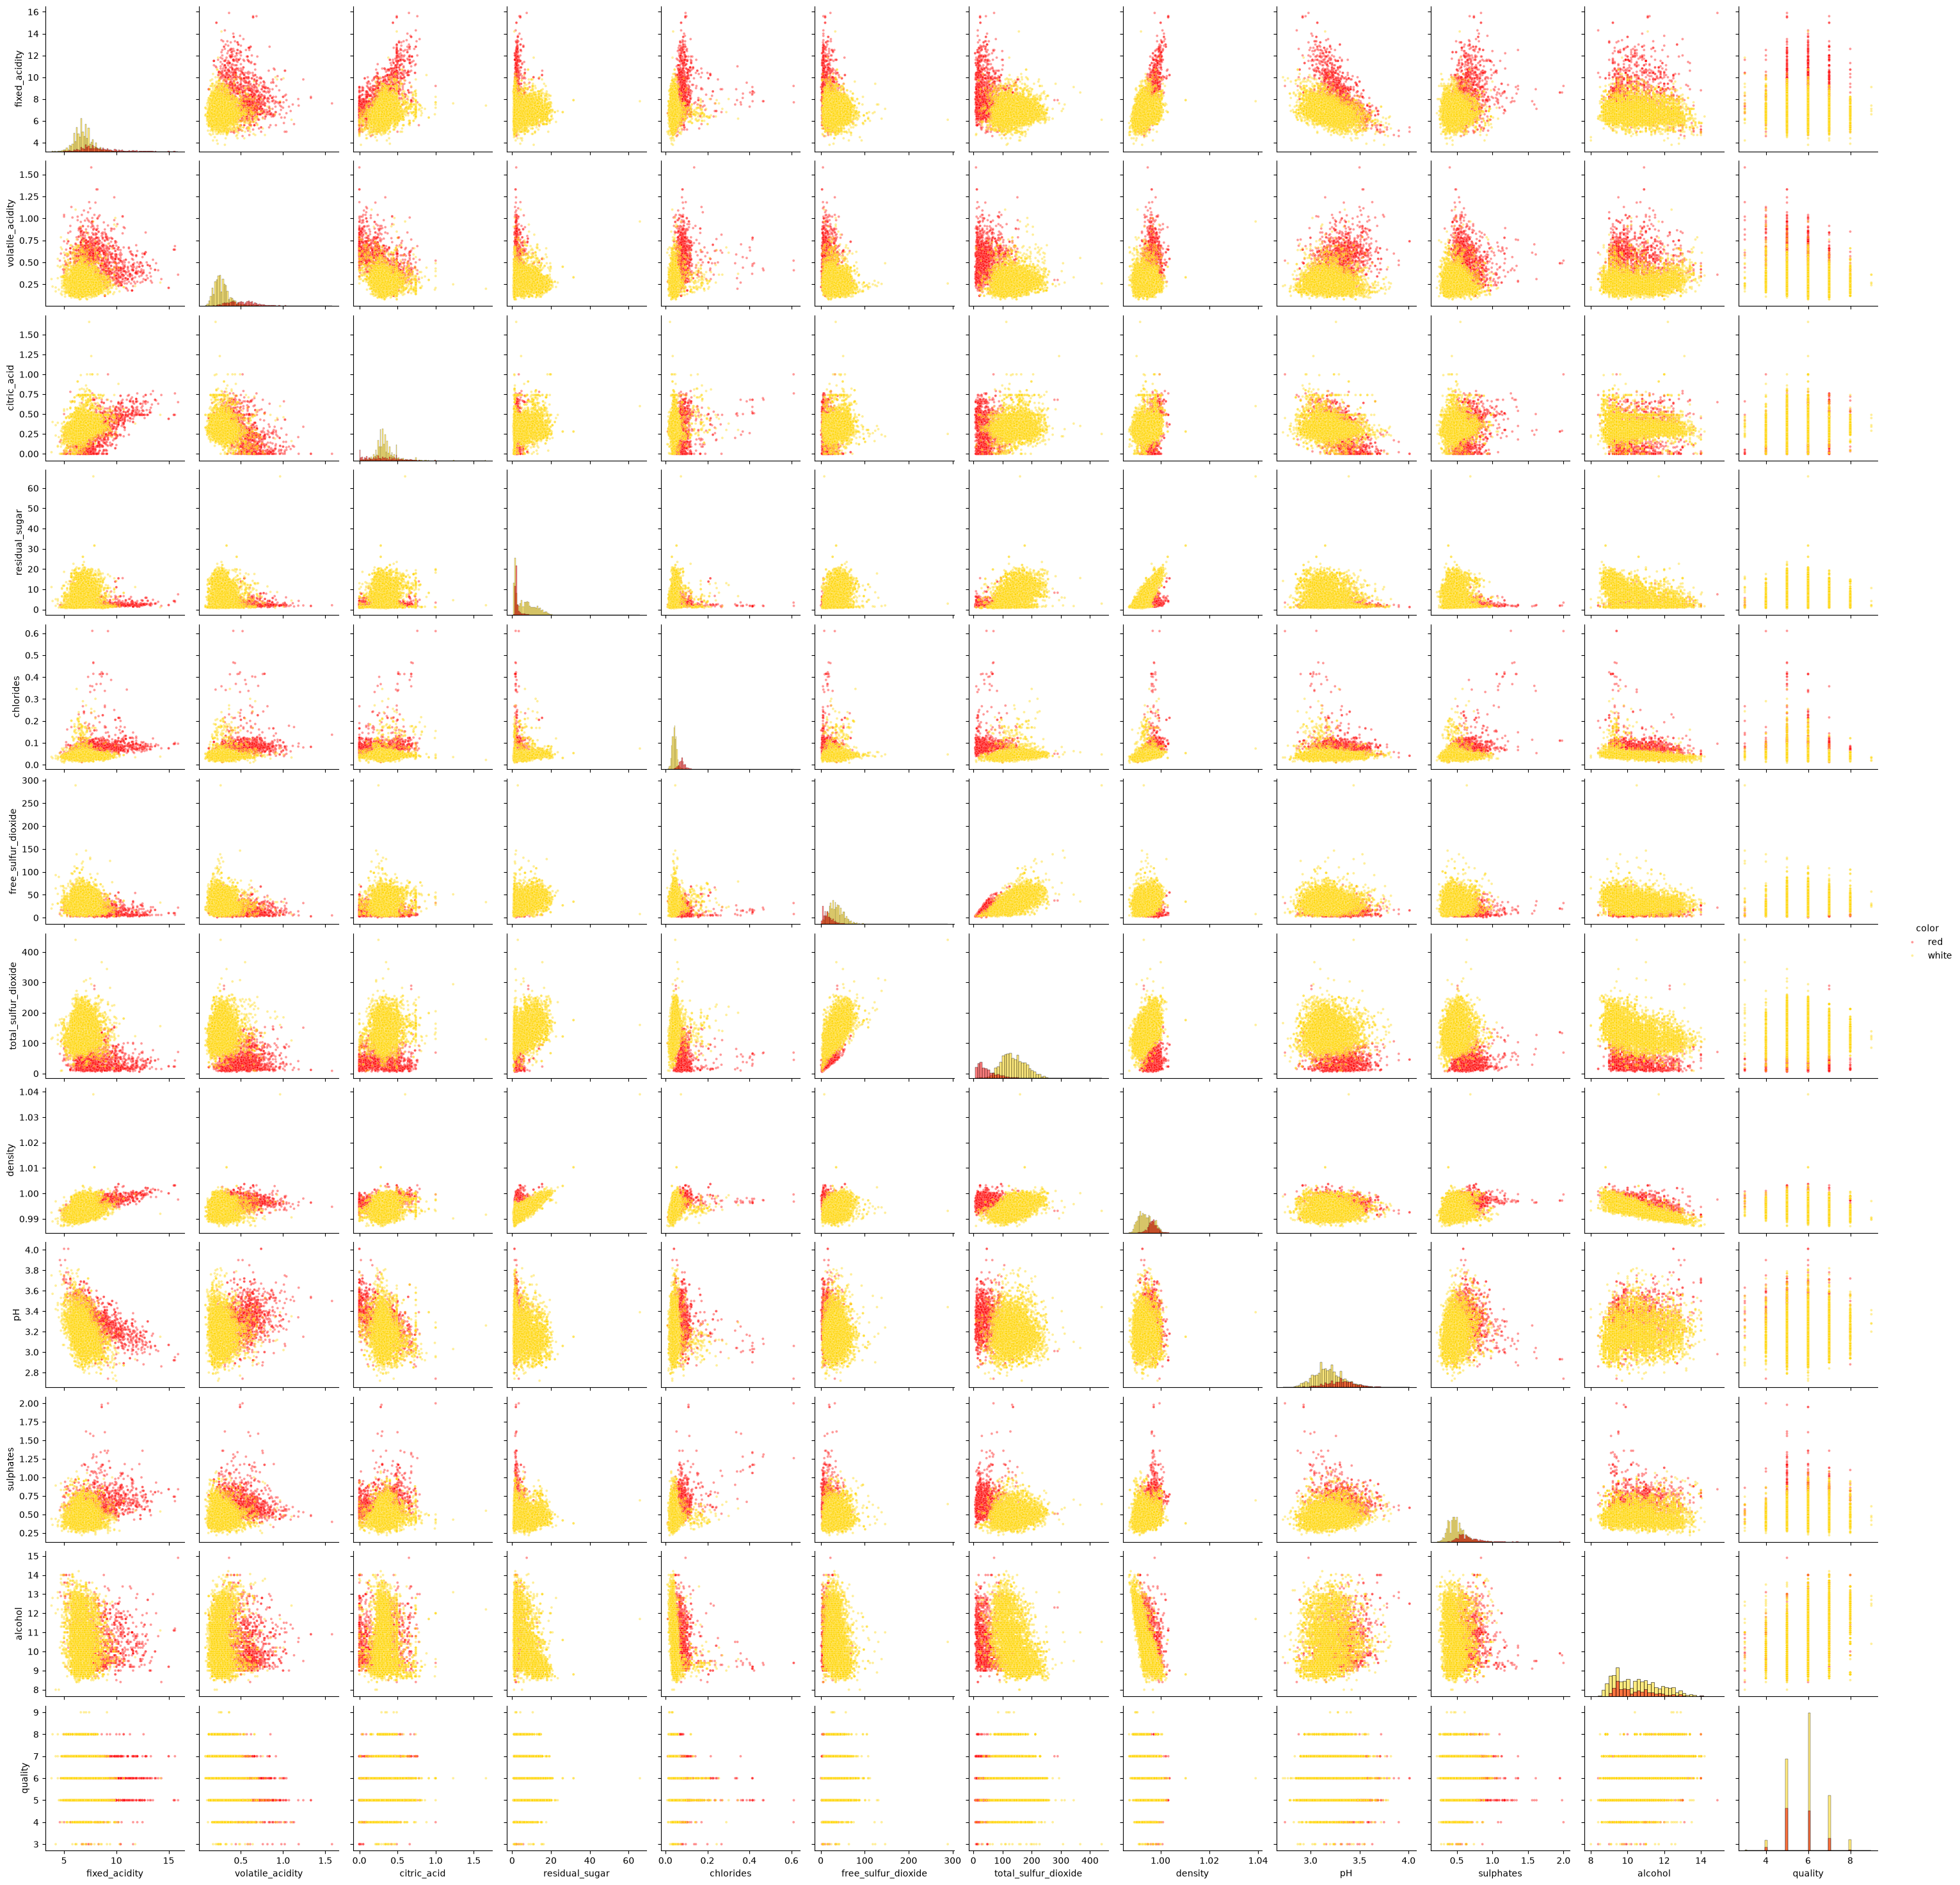

In [4]:
# Grafic pereche (pair plot) pentru setul de date
sns.pairplot(data, hue='color', diag_kind='hist',
             palette={'red': 'red', 'white': 'gold'},
             plot_kws={'s': 8, 'alpha': .4})
plt.show()

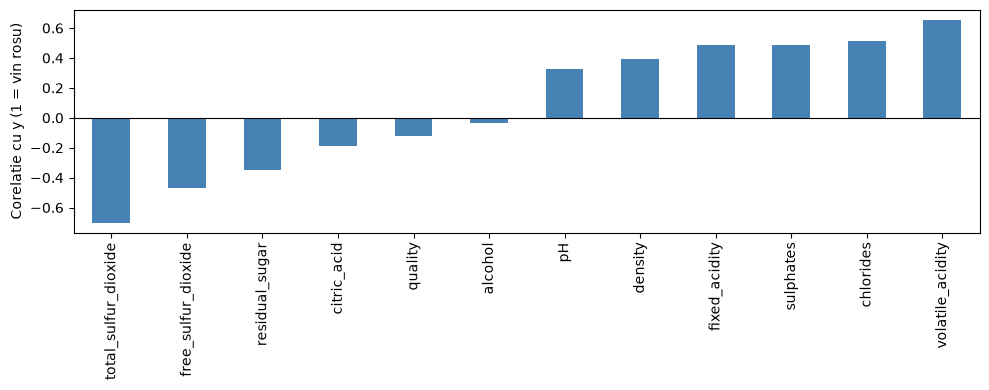

total_sulfur_dioxide   -0.700357
free_sulfur_dioxide    -0.471644
residual_sugar         -0.348821
citric_acid            -0.187397
quality                -0.119323
alcohol                -0.032970
pH                      0.329129
density                 0.390645
fixed_acidity           0.486740
sulphates               0.487218
chlorides               0.512678
volatile_acidity        0.653036
dtype: float64

In [5]:
# Grafic cu bare: corelatia dintre fiecare coloana numerica si y
correlations = data.drop(columns='color').corrwith(y).sort_values()

ax = correlations.plot.bar(figsize=(10, 4), color='steelblue')
ax.set_ylabel('Corelatie cu y (1 = vin rosu)')
ax.axhline(0, color='k', lw=.8)
plt.tight_layout()
plt.show()

correlations

In [6]:
# Cele doua campuri cu cea mai mare corelatie (valori absolute) -> X
top_fields = correlations.abs().sort_values(ascending=False).index[:2]
print('Campuri selectate:', list(top_fields))

X = data[top_fields]
X.head()

Campuri selectate: ['total_sulfur_dioxide', 'volatile_acidity']


,total_sulfur_dioxide,volatile_acidity
0,34.0,0.70
1,67.0,0.88
2,54.0,0.76
3,60.0,0.28
4,34.0,0.70


In [7]:
# Scalare cu MinMaxScaler; rezultatul (np.array) este transformat inapoi in DataFrame
X_scaled = MinMaxScaler().fit_transform(X)
X = pd.DataFrame(X_scaled, columns=X.columns)

X.describe().loc[['min', 'max']]

,total_sulfur_dioxide,volatile_acidity
min,0.0,0.0
max,1.0,1.0


## Întrebarea 2

Scopul acestei întrebări este de a analiza pragul de decizie al clasificatorului LinearSVC pentru setul de date dat. Consultați [acest exemplu](http://scikit-learn.org/stable/auto_examples/svm/plot_iris.html#sphx-glr-auto-examples-svm-plot-iris-py) din documentația sklearn.

* Configurați clasificatorul LinearSVC pe `X` și `y`.
* Selectați 300 de eșantioane din `X`. Obțineți valorile corespunzătoare ale `y`. Salvați-le în variabilele `X_color` și `y_color`. Acest lucru se datorează faptului că setul de date original este prea mare și generează un grafic supraîncărcat.
* Modificați `y_color` astfel încât valoarea „roșu” să înlocuiască 1, iar „galben” să înlocuiască 0.
* Graficul de dispersie pentru coloanele X_color. Utilizați argumentul cu cuvântul-cheie „color=y_color” pentru a afișa codul culorii.
* Utilizați fragmentul de cod de mai jos pentru a desena suprafața soluției în culori.


python

x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)

xx, yy = np.meshgrid(x_axis, y_axis)

xx_ravel = xx.ravel()

yy_ravel = yy.ravel()

X_grid = pd.DataFrame([xx_ravel, yy_ravel]). T

y_grid_predictions = *[MODELUL DVS.]*. predict(X_grid)

y_grid_predictions = y_grid_predictions.reshape(xx.shape)

ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)


Nu ezitați să experimentați cu diferite variante de parametri pentru LinearSVC și să examinați marginile de decizie.

In [8]:
# Configurarea clasificatorului LinearSVC pe X si y
linear_svc = LinearSVC()
linear_svc.fit(X, y)
print('Acuratete (train):', round(linear_svc.score(X, y), 4))

Acuratete (train): 0.9546


In [9]:
# 300 de esantioane din X + valorile y corespunzatoare
X_color = X.sample(300, random_state=42)
y_color = y.loc[X_color.index]

# 1 -> "red", 0 -> "yellow"
y_color = y_color.replace({1: 'red', 0: 'yellow'})
y_color.value_counts()

color
yellow    229
red        71
Name: count, dtype: int64

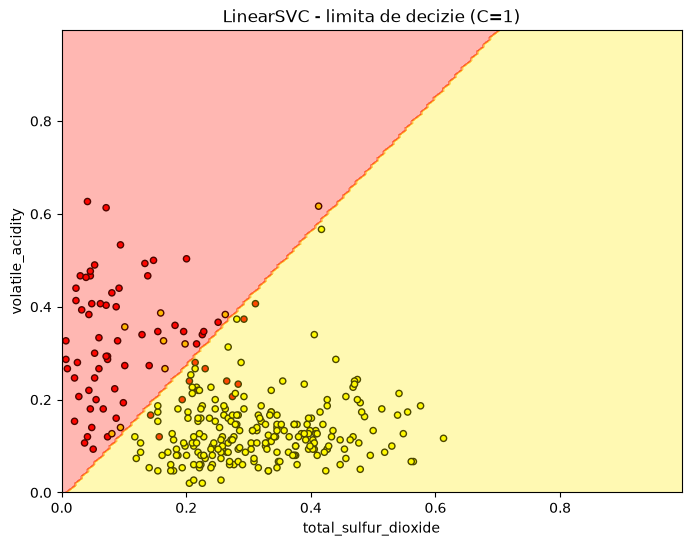

In [10]:
# Graficul de dispersie + suprafata solutiei
ax = X_color.plot.scatter(X_color.columns[0], X_color.columns[1],
                          color=y_color, figsize=(8, 6), edgecolor='k')

x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
X_grid.columns = X.columns      # aceleasi nume de coloane ca la antrenare

y_grid_predictions = linear_svc.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)

ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
ax.set_title('LinearSVC - limita de decizie (C=1)')
plt.show()

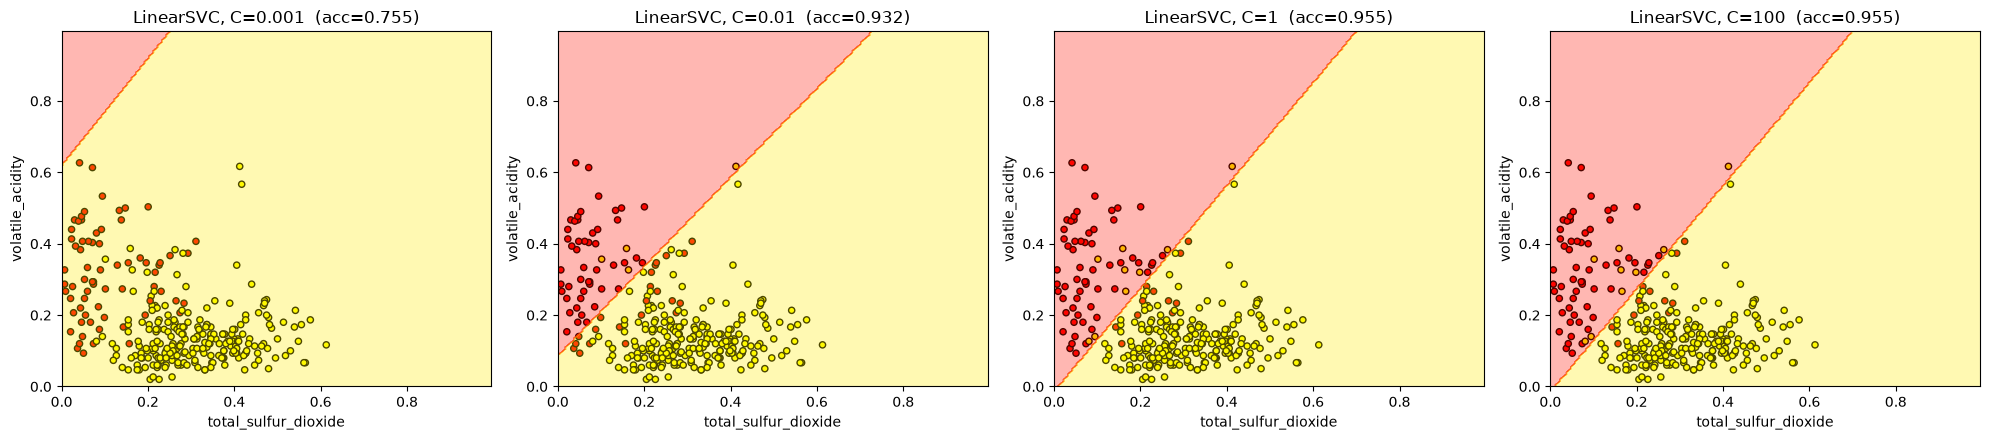

In [11]:
# Experimente cu diferiti parametri C pentru LinearSVC
Cs_linear = [.001, .01, 1, 100]
fig, axes = plt.subplots(1, len(Cs_linear), figsize=(20, 4.5))

for ax, C in zip(axes, Cs_linear):
    model = LinearSVC(C=C, max_iter=100000).fit(X, y)
    X_color.plot.scatter(X_color.columns[0], X_color.columns[1],
                         color=y_color, edgecolor='k', ax=ax)
    preds = model.predict(X_grid).reshape(xx.shape)
    ax.contourf(xx, yy, preds, cmap=plt.cm.autumn_r, alpha=.3)
    ax.set_title(f'LinearSVC, C={C}  (acc={model.score(X, y):.3f})')

plt.tight_layout()
plt.show()

## Întrebarea 3

Să extindem acum nucleul Gauss al SVC și să vedem cum se modifică limita de decizie.

* Combinați fragmentele de cod din întrebarea 2 într-o singură funcție, care utilizează estimatorul `X` și `y` și va genera graficul final cu limita de decizie. Pași:
    <ol>
     <li> modelul potrivit
     <li> obțineți un eșantion de 300 de înregistrări din X și valorile corespunzătoare ale lui y
     <li> creați o rețea, faceți predicții, generați un grafic folosind ax.contourf
     <li> adăugați-l la graficul dispersat
    </ol>
* După copierea și inserarea codului, asigurați-vă că funcția finală utilizează `estimatorul` dvs. de intrare, nu modelul LinearSVC creat de dvs.
* Pentru următoarele valori ale lui `gamma`, creați un SVC cu kernel gaussian și desenați curba de decizie.
`gammas = [.5, 1, 2, 10]`
* Menținând `gamma` constantă, pentru diferite valori ale lui `C`, desenați curba de decizie. Puteți încerca
`Cs = [.1, 1, 10]>

In [12]:
def plot_decision_boundary(estimator, X, y, ax=None, title=None,
                           n_samples=300, random_state=42):
    """Antreneaza `estimator` pe X, y si deseneaza limita de decizie
    peste un grafic de dispersie cu un esantion de n_samples inregistrari."""
    # 1. modelul potrivit
    estimator.fit(X, y)

    # 2. esantion de 300 de inregistrari din X si valorile y corespunzatoare
    X_color = X.sample(n_samples, random_state=random_state)
    y_color = y.loc[X_color.index].replace({1: 'red', 0: 'yellow'})

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))

    # graficul de dispersie
    X_color.plot.scatter(X_color.columns[0], X_color.columns[1],
                         color=y_color, edgecolor='k', ax=ax)

    # 3. retea (grid), predictii, ax.contourf
    x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
    xx, yy = np.meshgrid(x_axis, y_axis)
    X_grid = pd.DataFrame({X.columns[0]: xx.ravel(), X.columns[1]: yy.ravel()})

    y_grid_predictions = estimator.predict(X_grid).reshape(xx.shape)

    # 4. suprafata de decizie adaugata peste graficul de dispersie
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)

    acc = estimator.score(X, y)
    ax.set_title(f'{title}  (acc={acc:.3f})' if title else f'acc={acc:.3f}')
    return ax

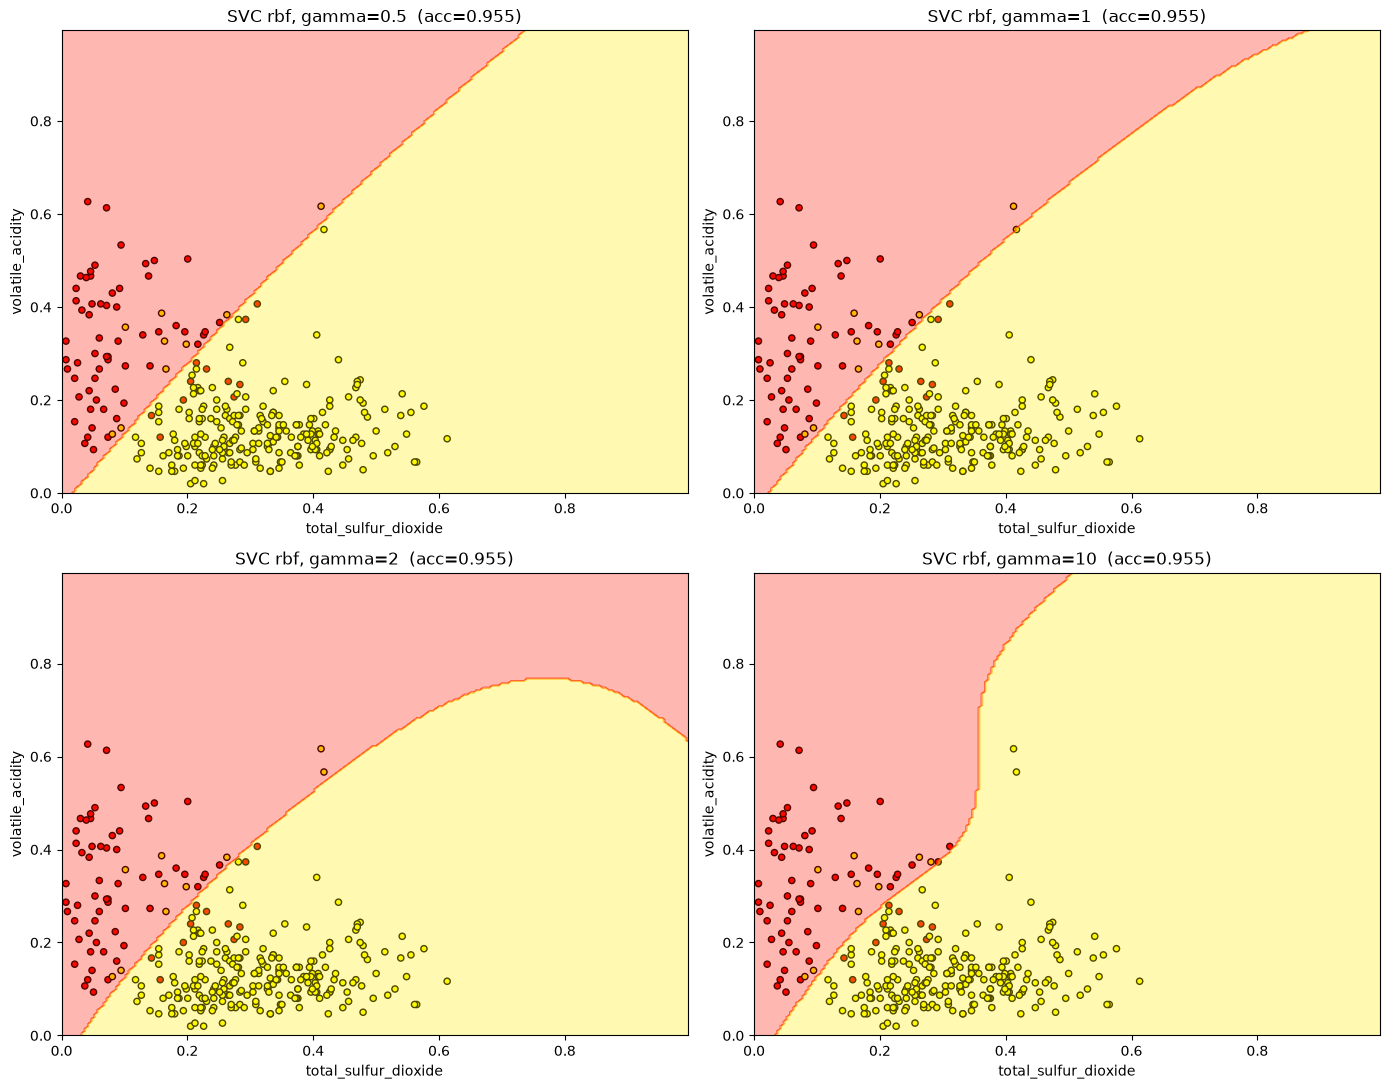

In [13]:
# Kernel gaussian (RBF) pentru diferite valori ale lui gamma
gammas = [.5, 1, 2, 10]

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, gamma in zip(axes.ravel(), gammas):
    plot_decision_boundary(SVC(kernel='rbf', gamma=gamma), X, y,
                           ax=ax, title=f'SVC rbf, gamma={gamma}')
plt.tight_layout()
plt.show()

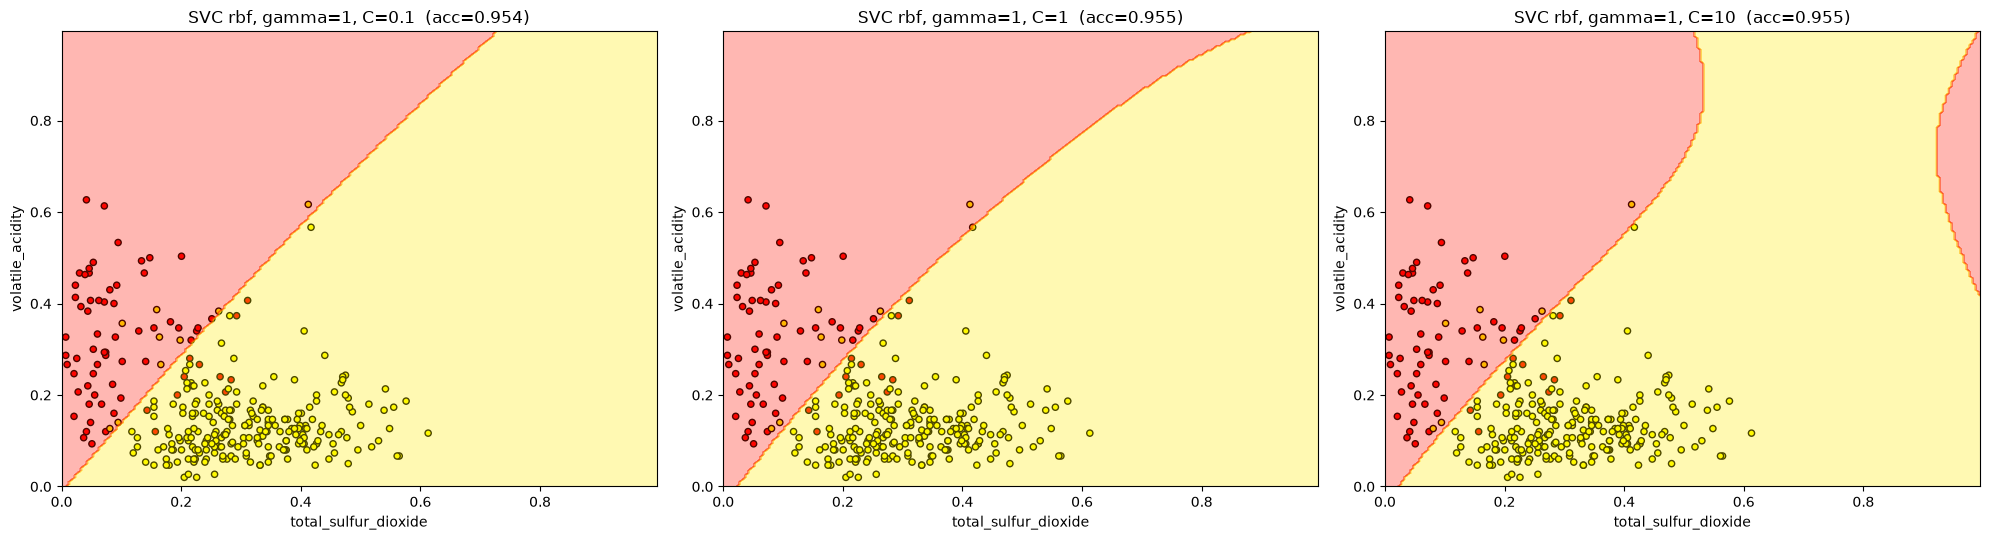

In [14]:
# gamma constant, diferite valori ale lui C
Cs = [.1, 1, 10]
gamma_fix = 1

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, C in zip(axes, Cs):
    plot_decision_boundary(SVC(kernel='rbf', gamma=gamma_fix, C=C), X, y,
                           ax=ax, title=f'SVC rbf, gamma={gamma_fix}, C={C}')
plt.tight_layout()
plt.show()

**Observații (Întrebarea 3)**
- Cu `gamma` mic (0.5, 1) limita de decizie este aproape liniară și netedă; pe măsură ce `gamma` crește (2, 10) frontiera devine tot mai curbată și mai locală (risc de supraînvățare).
- Cu `gamma` fix, un `C` mic (0.1) dă o frontieră mai simplă (margine mai largă, mai multă regularizare), iar un `C` mare (10) penalizează mai tare erorile și permite regiuni suplimentare, "izolate", pentru a clasifica corect câteva puncte.

## Întrebarea 4

În această întrebare vom compara timpul de execuție între SVC și Nystroem cu nucleul rbf.
<br><br>
Jupyter Notebooks oferă o funcție magică utilă, **`%timeit`**, care execută un șir de comandă și afișează timpul necesar pentru execuție. Dacă introduceți **`%timeit`** la începutul unei celule, aceasta va rula întreaga celulă și va afișa timpul de execuție.

* Reîncărcați datele privind calitatea vinului dacă ați adus modificări la original.
* Creați variabila `y` din coloana `data.color` și `X` din celelalte coloane.
* Folosiți `%%timeit` pentru a măsura timpul necesar configurării SVC cu nucleul RBF.
* Folosiți `%%timeit` pentru a măsura timpul necesar următoarei operațiuni: ordonați datele folosind Nystroem, apoi integrați clasificatorul SGD.

Nystroem+SGD va necesita mult mai puțin timp pentru antrenare. Această diferență va fi mai pronunțată dacă setul de date ar fi mai mare.

* Faceți 5 copii ale lui X și corelați-le
* Faceți 5 copii ale lui y și corelați-le
* Comparați timpul necesar pentru antrenarea ambelor metode de mai sus.

In [15]:
# Reincarcarea datelor
data = pd.read_csv('Wine_Quality_Data.csv')

# y din coloana data.color, X din celelalte coloane
y = (data.color == 'red').astype(int)
X = data.drop(columns='color')

# Scalam caracteristicile in [0, 1] (necesar pentru un kernel RBF cu gamma fix)
X_scaled = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)
gamma = .5

print(X_scaled.shape, y.shape)

(6497, 12) (6497,)


In [16]:
%%timeit
# Timpul de antrenare: SVC cu nucleu RBF
svc = SVC(kernel='rbf', gamma=gamma)
svc.fit(X_scaled, y)

166 ms ± 6.9 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [17]:
%%timeit
# Timpul de antrenare: Nystroem (aproximare a kernelului RBF) + SGDClassifier
nystroem = Nystroem(kernel='rbf', gamma=gamma, n_components=100, random_state=42)
X_transformed = nystroem.fit_transform(X_scaled)
sgd = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)
sgd.fit(X_transformed, y)

43.2 ms ± 1.17 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [18]:
# Verificare (netemporizata): acuratetea celor doua modele
svc = SVC(kernel='rbf', gamma=gamma).fit(X_scaled, y)

nystroem = Nystroem(kernel='rbf', gamma=gamma, n_components=100, random_state=42)
X_transformed = nystroem.fit_transform(X_scaled)
sgd = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42).fit(X_transformed, y)

print('SVC (rbf)         acuratete:', round(svc.score(X_scaled, y), 4))
print('Nystroem + SGD    acuratete:', round(sgd.score(X_transformed, y), 4))

SVC (rbf)         acuratete: 0.9934
Nystroem + SGD    acuratete: 0.9931


In [19]:
# 5 copii ale lui X si 5 copii ale lui y, corelate (concatenate)
X_5 = pd.concat([X_scaled] * 5, ignore_index=True)
y_5 = pd.concat([y] * 5, ignore_index=True)

print(X_5.shape, y_5.shape)

(32485, 12) (32485,)


In [20]:
%%timeit -n 1 -r 3
# SVC cu nucleu RBF pe setul de date de 5 ori mai mare
svc = SVC(kernel='rbf', gamma=gamma)
svc.fit(X_5, y_5)

2.32 s ± 27.9 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


In [21]:
%%timeit -n 1 -r 3
# Nystroem + SGDClassifier pe setul de date de 5 ori mai mare
nystroem = Nystroem(kernel='rbf', gamma=gamma, n_components=100, random_state=42)
X_5_transformed = nystroem.fit_transform(X_5)
sgd = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)
sgd.fit(X_5_transformed, y_5)

180 ms ± 12.9 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)


**Observații (Întrebarea 4)**
- Nystroem + SGD atinge practic aceeași acuratețe ca SVC cu kernel RBF (~0.993), dar se antrenează mai rapid.
- Diferența crește cu dimensiunea setului de date: SVC are o complexitate de antrenare supraliniară în numărul de eșantioane, în timp ce Nystroem + SGD scalează aproximativ liniar. La rularea noastră raportul a fost de ~3x pe setul original și de ~9x pe setul de 5 ori mai mare (valorile exacte depind de mașină).